# Classification V1 — 최종 Baseline

## 목적

서울 25개 구의 **향후 3개월 시장 상승 가능성**을 예측하는 Classification Baseline을 구축한다.

최종 Target은 다음과 같이 정의한다.

- **0 = 비상승**
- **1 = 향후 3개월 지역 중위 평당가가 +3% 초과 상승**

초기에는 `하락 / 보합 / 상승` 3-Class 문제도 실험했지만,
최종 V1에서는 비즈니스 목적이 더 명확한 **Binary Classification**만 남긴다.

### V1 평가 원칙

- 현재 시점까지 확정된 정보만 Feature로 사용
- 미래 가격 관련 컬럼은 Feature에서 제거
- 시간순 Rolling Backtest 사용
- Expanding Window와 최근 18/24/30/36개월 Window 비교
- 최종 V1은 가장 좋은 평균 ROC-AUC를 기록한 **18개월 Rolling Window**로 확정


## 전체 흐름

1. 데이터 로드 및 월 기준 생성
2. 구 × 월 시장가격 집계
3. 향후 3개월 변화율 및 Binary Target 생성
4. 과거 매매·전월세·금리·정책 Feature 생성
5. 서울 전체 시장 국면 Feature 추가
6. Leakage Check
7. Rolling Backtest
8. Window 비교 및 해석
9. 최근 18개월 데이터로 최종 모델 재학습
10. V1 Artifact 저장


In [76]:
# ============================================================
# 1. 기본 설정 / 데이터 로드
# ============================================================

from pathlib import Path
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from xgboost import XGBClassifier


plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


PROJECT_DIR = Path.cwd().parents[3]

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "v2_5year_seoul"
    / "processed"
    / "df_final_v1.parquet"
)

df = pd.read_parquet(DATA_PATH)

df["거래월일자"] = pd.to_datetime(df["거래월일자"])
df["기준월"] = df["거래월일자"].dt.to_period("M")

print("데이터:", df.shape)
print("기간:", df["거래월일자"].min(), "~", df["거래월일자"].max())


데이터: (234302, 125)
기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00


In [77]:
# ============================================================
# 2. 서울 25개 구 매핑
# ============================================================

gu_map = {
    11110: "종로구", 11140: "중구", 11170: "용산구", 11200: "성동구",
    11215: "광진구", 11230: "동대문구", 11260: "중랑구", 11290: "성북구",
    11305: "강북구", 11320: "도봉구", 11350: "노원구", 11380: "은평구",
    11410: "서대문구", 11440: "마포구", 11470: "양천구", 11500: "강서구",
    11530: "구로구", 11545: "금천구", 11560: "영등포구", 11590: "동작구",
    11620: "관악구", 11650: "서초구", 11680: "강남구", 11710: "송파구",
    11740: "강동구",
}

df["시군구코드"] = pd.to_numeric(
    df["법정동시군구코드"],
    errors="coerce",
).astype("Int64")

df["구"] = df["시군구코드"].map(gu_map)

assert df["구"].nunique() == 25
assert df["구"].isna().sum() == 0

print("서울 구 개수:", df["구"].nunique())


서울 구 개수: 25


In [ ]:
# ============================================================
# 3. 구 × 월 시장가격 + 향후 3개월 변화율
# ============================================================

gu_month_df = (
    df
    .groupby(["구", "기준월"], observed=True)
    .agg(
        거래건수=("transaction_id", "size"),
        월중위평당가=("평당가", "median"),
    )
    .reset_index()
    .sort_values(["구", "기준월"])
    .reset_index(drop=True)
)

grouped_gu = gu_month_df.groupby("구")

# 현재월 포함 최근 3개월 대표 가격
gu_month_df["최근3개월_평당가"] = (
    grouped_gu["월중위평당가"]
    .transform(lambda x: x.rolling(3, min_periods=3).median())
)

# Target 계산용 미래 가격
for month in [1, 2, 3]:
    gu_month_df[f"미래{month}개월_평당가"] = (
        grouped_gu["월중위평당가"].shift(-month)
    )

future_cols = [
    "미래1개월_평당가",
    "미래2개월_평당가",
    "미래3개월_평당가",
]

gu_month_df["향후3개월_평당가"] = (
    gu_month_df[future_cols].median(axis=1)
)

target_available_mask = (
    gu_month_df["최근3개월_평당가"].notna()
    & gu_month_df[future_cols].notna().all(axis=1)
)

gu_month_df["향후3개월_변화율"] = np.nan

gu_month_df.loc[target_available_mask, "향후3개월_변화율"] = (
    gu_month_df.loc[target_available_mask, "향후3개월_평당가"]
    / gu_month_df.loc[target_available_mask, "최근3개월_평당가"]
    - 1
)

target_market_df = gu_month_df.loc[target_available_mask].copy()

print("전체 구×월:", f"{len(gu_month_df):,}")
print("Target 사용 가능:", f"{len(target_market_df):,}")
print(
    "Target 기간:",
    target_market_df["기준월"].min(),
    "~",
    target_market_df["기준월"].max(),
)


전체 구×월: 1,500
Target 사용 가능: 1,375
Target 기간: 2021-09 ~ 2026-03


In [79]:
# ============================================================
# 4. +3% Threshold 확인 / Binary Target 확정
# ============================================================

threshold_results = []

for threshold in [0.01, 0.02, 0.03]:
    change = target_market_df["향후3개월_변화율"]

    threshold_results.append({
        "기준": f"±{threshold * 100:.0f}%",
        "하락_%": (change < -threshold).mean() * 100,
        "보합_%": (change.abs() <= threshold).mean() * 100,
        "상승_%": (change > threshold).mean() * 100,
    })

threshold_compare = pd.DataFrame(threshold_results)
display(threshold_compare.round(2))


BINARY_TARGET = "상승여부"

target_market_df[BINARY_TARGET] = (
    target_market_df["향후3개월_변화율"] > 0.03
).astype("int8")

binary_distribution = (
    target_market_df[BINARY_TARGET]
    .value_counts()
    .sort_index()
    .rename(index={0: "비상승", 1: "상승"})
    .to_frame("구×월")
)

binary_distribution["비율_%"] = (
    binary_distribution["구×월"]
    / len(target_market_df)
    * 100
)

display(binary_distribution.round(2))


,기준,하락_%,보합_%,상승_%
0,±1%,39.42,10.33,50.25
1,±2%,33.24,24.00,42.76
2,±3%,28.29,34.40,37.31


,구×월,비율_%
상승여부,,
비상승,862,62.69
상승,513,37.31


### Target 해석

최종 V1은 **향후 3개월 +3% 초과 상승 여부**를 예측한다.

현재 데이터에서는 약 **37.3%가 상승**, 약 **62.7%가 비상승**으로,
완전한 균형 데이터는 아니지만 극단적인 불균형 수준은 아니다.

`+3%` 기준은 단순한 미세 변동을 상승 신호로 처리하지 않고,
실질적인 시장 상승 국면을 구분하기 위한 Baseline Threshold로 사용한다.

> Feature는 기준월까지 확인 가능한 정보만 사용하고,
> 향후 1~3개월 가격은 Target 생성에만 사용한다.


In [80]:
# ============================================================
# 5. 구 × 월 과거 매매 Feature
# ============================================================

market_feature_df = (
    gu_month_df
    .sort_values(["구", "기준월"])
    .copy()
)

grouped = market_feature_df.groupby("구")

# 가격 Lag
for lag in [1, 3, 6]:
    market_feature_df[f"평당가_lag{lag}"] = (
        grouped["월중위평당가"].shift(lag)
    )

# 과거 가격 변화율
for lag in [1, 3, 6]:
    market_feature_df[f"평당가_{lag}개월변화율"] = (
        market_feature_df["월중위평당가"]
        / market_feature_df[f"평당가_lag{lag}"]
        - 1
    )

# Rolling 가격 / 변동성
market_feature_df["최근3개월_중위평당가"] = (
    grouped["월중위평당가"]
    .transform(lambda x: x.rolling(3, min_periods=3).median())
)

market_feature_df["최근6개월_중위평당가"] = (
    grouped["월중위평당가"]
    .transform(lambda x: x.rolling(6, min_periods=6).median())
)

market_feature_df["최근6개월_가격변동성"] = (
    grouped["월중위평당가"]
    .transform(lambda x: x.rolling(6, min_periods=6).std())
)

# 거래량
market_feature_df["거래건수_lag1"] = grouped["거래건수"].shift(1)

market_feature_df["최근3개월_평균거래량"] = (
    grouped["거래건수"]
    .transform(lambda x: x.rolling(3, min_periods=3).mean())
)

market_feature_df["최근6개월_평균거래량"] = (
    grouped["거래건수"]
    .transform(lambda x: x.rolling(6, min_periods=6).mean())
)

market_feature_df["거래량_전월대비"] = (
    market_feature_df["거래건수"]
    / market_feature_df["거래건수_lag1"]
    - 1
)

market_feature_df["거래량_3개월평균대비"] = (
    market_feature_df["거래건수"]
    / market_feature_df["최근3개월_평균거래량"]
    - 1
)

# 미래 정보 제거
future_target_cols = [
    "미래1개월_평당가",
    "미래2개월_평당가",
    "미래3개월_평당가",
    "향후3개월_평당가",
    "향후3개월_변화율",
    "최근3개월_평당가",
]

market_feature_df = market_feature_df.drop(
    columns=[col for col in future_target_cols if col in market_feature_df.columns]
)


In [81]:
# ============================================================
# 6. 전월세 / 금리 / 정책 Feature
# ============================================================

rent_feature_cols = [
    "전세평당가_전월",
    "전세평당가_과거3개월",
    "전세평당가_과거6개월",
    "전세거래량_전월",
    "전세거래량_과거3개월",
    "전세거래량_과거6개월",
    "전세가율_전월",
    "전세가율_과거3개월",
    "전세가율_과거6개월",
]

rate_feature_cols = [
    "기준금리_전월",
    "기준금리_3개월변화",
    "기준금리_6개월변화",
    "주담대금리_전월",
    "주담대금리_3개월변화",
    "주담대금리_6개월변화",
    "전세대출금리_전월",
    "전세대출금리_3개월변화",
    "전세대출금리_6개월변화",
]

monthly_policy_cols = [
    "DSR단계",
    "스트레스DSR단계",
    "주담대규제강화여부",
]

rent_month_df = (
    df
    .groupby(["구", "기준월"], observed=True)[rent_feature_cols]
    .median()
    .reset_index()
)

rate_month_df = (
    df[["기준월"] + rate_feature_cols]
    .drop_duplicates(subset=["기준월"])
    .sort_values("기준월")
    .reset_index(drop=True)
)

policy_month_df = (
    df
    .groupby("기준월")[monthly_policy_cols]
    .first()
    .reset_index()
)

regulation_gu_month_df = (
    df
    .groupby(["구", "기준월"], observed=True)["규제지역여부"]
    .first()
    .reset_index()
)

print("전월세:", rent_month_df.shape)
print("금리:", rate_month_df.shape)
print("월 정책:", policy_month_df.shape)
print("구×월 규제지역:", regulation_gu_month_df.shape)


전월세: (1500, 11)
금리: (60, 10)
월 정책: (60, 4)
구×월 규제지역: (1500, 3)


In [82]:
# ============================================================
# 7. 서울 전체 시장 국면 Feature
# ============================================================

seoul_market_df = (
    gu_month_df
    .groupby("기준월")
    .agg(
        서울_중위평당가=("월중위평당가", "median"),
        서울_거래건수=("거래건수", "sum"),
    )
    .sort_index()
    .reset_index()
)

for lag in [1, 3, 6]:
    seoul_market_df[f"서울_평당가_lag{lag}"] = (
        seoul_market_df["서울_중위평당가"].shift(lag)
    )
    seoul_market_df[f"서울_{lag}개월변화율"] = (
        seoul_market_df["서울_중위평당가"]
        / seoul_market_df[f"서울_평당가_lag{lag}"]
        - 1
    )

# 시장 Breadth
breadth_df = (
    market_feature_df
    .groupby("기준월")
    .agg(
        상승구비율=("평당가_3개월변화율", lambda x: (x > 0).mean()),
        강한상승구비율=("평당가_3개월변화율", lambda x: (x > 0.03).mean()),
        강한하락구비율=("평당가_3개월변화율", lambda x: (x < -0.03).mean()),
    )
    .reset_index()
)

seoul_market_df = seoul_market_df.merge(
    breadth_df,
    on="기준월",
    how="left",
    validate="one_to_one",
)

# t-3 시점의 '향후 3개월 변화율'은 현재 t에서 모두 확정된 과거 정보
confirmed_market_df = (
    gu_month_df[["구", "기준월", "향후3개월_변화율"]]
    .sort_values(["구", "기준월"])
    .copy()
)

confirmed_market_df["직전확정_3개월변화율"] = (
    confirmed_market_df
    .groupby("구")["향후3개월_변화율"]
    .shift(3)
)

confirmed_market_df = confirmed_market_df[
    ["구", "기준월", "직전확정_3개월변화율"]
]


In [83]:
# ============================================================
# 8. 최종 Classification Feature Table
# ============================================================

classification_feature_df = (
    market_feature_df
    .merge(
        rent_month_df,
        on=["구", "기준월"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        rate_month_df,
        on="기준월",
        how="left",
        validate="many_to_one",
    )
    .merge(
        policy_month_df,
        on="기준월",
        how="left",
        validate="many_to_one",
    )
    .merge(
        regulation_gu_month_df,
        on=["구", "기준월"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        seoul_market_df,
        on="기준월",
        how="left",
        validate="many_to_one",
    )
    .merge(
        confirmed_market_df,
        on=["구", "기준월"],
        how="left",
        validate="one_to_one",
    )
)

target_cols = [
    "구",
    "기준월",
    "향후3개월_변화율",
    BINARY_TARGET,
]

classification_model_v1_df = (
    classification_feature_df
    .merge(
        target_market_df[target_cols],
        on=["구", "기준월"],
        how="inner",
        validate="one_to_one",
    )
    .sort_values(["기준월", "구"])
    .reset_index(drop=True)
)

print("모델링 데이터:", classification_model_v1_df.shape)
print(
    "기간:",
    classification_model_v1_df["기준월"].min(),
    "~",
    classification_model_v1_df["기준월"].max(),
)


모델링 데이터: (1375, 54)
기간: 2021-09 ~ 2026-03


In [84]:
# ============================================================
# 9. Feature 확정 + Leakage Check
# ============================================================

EXCLUDE_COLS = {
    "기준월",
    "향후3개월_변화율",
    BINARY_TARGET,
}

feature_v1_cols = [
    col
    for col in classification_model_v1_df.columns
    if col not in EXCLUDE_COLS
]

categorical_v1_cols = ["구"]

leak_cols = [
    col
    for col in feature_v1_cols
    if (
        "미래" in col
        or "향후" in col
        or "상승여부" in col
    )
]

assert not leak_cols, f"누수 의심 Feature 발견: {leak_cols}"

missing_summary = (
    classification_model_v1_df[feature_v1_cols]
    .isna()
    .sum()
)

missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)

print("Feature:", len(feature_v1_cols))
print("누수 의심:", leak_cols)
print("구×월 중복:", classification_model_v1_df[["구", "기준월"]].duplicated().sum())

if len(missing_summary):
    display(missing_summary.to_frame("결측건수").head(20))
else:
    print("Feature 결측 없음")


Feature: 51
누수 의심: []
구×월 중복: 0


,결측건수
평당가_lag6,100
평당가_6개월변화율,100
서울_6개월변화율,100
서울_평당가_lag6,100
최근6개월_중위평당가,75
직전확정_3개월변화율,75
최근6개월_평균거래량,75
최근6개월_가격변동성,75
평당가_lag3,25
평당가_3개월변화율,25


### Leakage Check 해석

Classification V1은 **현재 시점까지 확인 가능한 정보만 Feature로 사용**한다.

- 미래 1~3개월 가격은 Target 계산에만 사용
- `향후3개월_변화율`, `상승여부`는 Feature에서 명시적으로 제외
- 가격·거래량·전월세·금리 Feature는 현재 또는 과거 시점 정보
- `직전확정_3개월변화율`은 3개월 shift 후 사용하므로 기준월 시점에 이미 확정된 과거 정보

따라서 Backtest에서 미래 정보가 Feature로 직접 유입되지 않도록 구성한다.


In [85]:
# ============================================================
# 10. Rolling Backtest 함수
# ============================================================

backtest_periods = [
    {
        "name": "Fold1",
        "train_end": "2023-06",
        "valid_start": "2023-10",
        "valid_end": "2024-03",
    },
    {
        "name": "Fold2",
        "train_end": "2023-12",
        "valid_start": "2024-04",
        "valid_end": "2024-09",
    },
    {
        "name": "Fold3",
        "train_end": "2024-06",
        "valid_start": "2024-10",
        "valid_end": "2025-03",
    },
    {
        "name": "Fold4",
        "train_end": "2024-12",
        "valid_start": "2025-04",
        "valid_end": "2025-09",
    },
]


def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "gu",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_v1_cols,
            ),
        ],
        remainder="passthrough",
    )


def make_classifier():
    return XGBClassifier(
        objective="binary:logistic",
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_child_weight=1,
        subsample=1.0,
        colsample_bytree=1.0,
        reg_alpha=0.0,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    )


def run_backtest(window_months=None):
    results = []

    for period in backtest_periods:
        train_end = pd.Period(period["train_end"], freq="M")
        valid_start = pd.Period(period["valid_start"], freq="M")
        valid_end = pd.Period(period["valid_end"], freq="M")

        if window_months is None:
            fold_train = classification_model_v1_df[
                classification_model_v1_df["기준월"] <= train_end
            ].copy()
            window_name = "Expanding"
        else:
            train_start = train_end - (window_months - 1)
            fold_train = classification_model_v1_df[
                classification_model_v1_df["기준월"].between(
                    train_start,
                    train_end,
                )
            ].copy()
            window_name = f"{window_months}M"

        fold_valid = classification_model_v1_df[
            classification_model_v1_df["기준월"].between(
                valid_start,
                valid_end,
            )
        ].copy()

        X_train_raw = fold_train[feature_v1_cols]
        X_valid_raw = fold_valid[feature_v1_cols]

        y_train = fold_train[BINARY_TARGET]
        y_valid = fold_valid[BINARY_TARGET]

        preprocessor = make_preprocessor()

        X_train = preprocessor.fit_transform(X_train_raw)
        X_valid = preprocessor.transform(X_valid_raw)

        model = make_classifier()
        model.fit(X_train, y_train, verbose=False)

        pred = model.predict(X_valid)
        prob = model.predict_proba(X_valid)[:, 1]

        results.append({
            "Window": window_name,
            "Fold": period["name"],
            "Train": len(fold_train),
            "Valid": len(fold_valid),
            "Accuracy": accuracy_score(y_valid, pred),
            "Balanced Accuracy": balanced_accuracy_score(y_valid, pred),
            "F1": f1_score(y_valid, pred, zero_division=0),
            "Precision": precision_score(y_valid, pred, zero_division=0),
            "상승 Recall": recall_score(y_valid, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_valid, prob),
        })

    return pd.DataFrame(results)


In [86]:
# ============================================================
# 11. Expanding + Rolling Window 비교
# ============================================================

expanding_backtest_df = run_backtest(window_months=None)

rolling_frames = [
    run_backtest(window_months=window)
    for window in [18, 24, 30, 36]
]

rolling_backtest_df = pd.concat(
    rolling_frames,
    ignore_index=True,
)

window_summary = (
    rolling_backtest_df
    .groupby("Window")
    .agg(
        평균_Balanced_Accuracy=("Balanced Accuracy", "mean"),
        평균_F1=("F1", "mean"),
        평균_상승_Recall=("상승 Recall", "mean"),
        평균_ROC_AUC=("ROC AUC", "mean"),
        최소_ROC_AUC=("ROC AUC", "min"),
    )
    .sort_values("평균_ROC_AUC", ascending=False)
)

rolling_18m_df = (
    rolling_backtest_df[
        rolling_backtest_df["Window"] == "18M"
    ]
    .reset_index(drop=True)
)

print("===== Rolling Window 평균 성능 =====")
display(window_summary.round(3))

print("\n===== 18개월 Rolling Fold별 성능 =====")
display(
    rolling_18m_df[
        [
            "Fold",
            "Train",
            "Valid",
            "Balanced Accuracy",
            "F1",
            "Precision",
            "상승 Recall",
            "ROC AUC",
        ]
    ].round(3)
)

print("\n===== Expanding vs 18개월 Rolling =====")
window_compare = pd.concat(
    [
        expanding_backtest_df.assign(학습방식="Expanding"),
        rolling_18m_df.assign(학습방식="18개월 Rolling"),
    ],
    ignore_index=True,
)

display(
    window_compare[
        [
            "Fold",
            "학습방식",
            "Balanced Accuracy",
            "F1",
            "상승 Recall",
            "ROC AUC",
        ]
    ].round(3)
)


===== Rolling Window 평균 성능 =====


,평균_Balanced_Accuracy,평균_F1,평균_상승_Recall,평균_ROC_AUC,최소_ROC_AUC
Window,,,,,
18M,0.548,0.376,0.357,0.613,0.422
24M,0.548,0.335,0.308,0.591,0.401
36M,0.533,0.313,0.287,0.558,0.321
30M,0.538,0.329,0.299,0.555,0.322



===== 18개월 Rolling Fold별 성능 =====


,Fold,Train,Valid,Balanced Accuracy,F1,Precision,상승 Recall,ROC AUC
0,Fold1,450,150,0.678,0.632,0.558,0.729,0.742
1,Fold2,450,150,0.572,0.304,0.750,0.190,0.720
2,Fold3,450,150,0.460,0.214,0.393,0.147,0.567
3,Fold4,450,150,0.482,0.354,0.345,0.364,0.422



===== Expanding vs 18개월 Rolling =====


,Fold,학습방식,Balanced Accuracy,F1,상승 Recall,ROC AUC
0,Fold1,Expanding,0.647,0.604,0.712,0.707
1,Fold2,Expanding,0.612,0.405,0.270,0.679
2,Fold3,Expanding,0.473,0.151,0.093,0.524
3,Fold4,Expanding,0.415,0.098,0.073,0.307
4,Fold1,18개월 Rolling,0.678,0.632,0.729,0.742
5,Fold2,18개월 Rolling,0.572,0.304,0.190,0.720
6,Fold3,18개월 Rolling,0.460,0.214,0.147,0.567
7,Fold4,18개월 Rolling,0.482,0.354,0.364,0.422


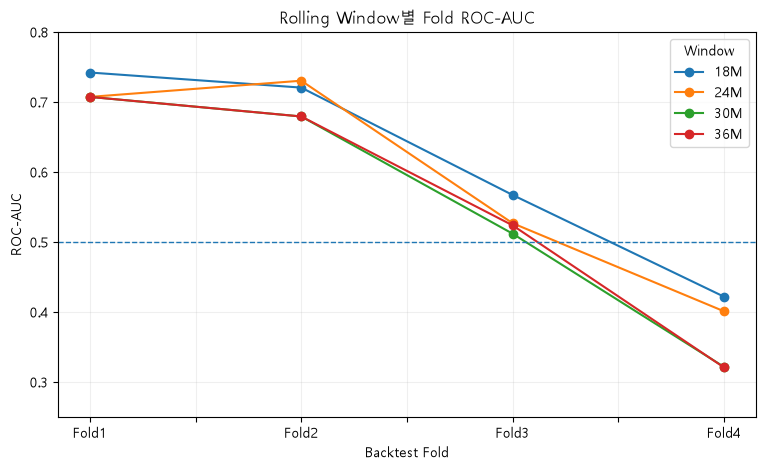

In [87]:
# ============================================================
# 12. Fold별 ROC-AUC 변화
# ============================================================

auc_plot_df = rolling_backtest_df.pivot(
    index="Fold",
    columns="Window",
    values="ROC AUC",
)

auc_plot_df.plot(
    marker="o",
    figsize=(9, 5),
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
)

plt.title("Rolling Window별 Fold ROC-AUC")
plt.xlabel("Backtest Fold")
plt.ylabel("ROC-AUC")
plt.ylim(0.25, 0.80)
plt.grid(alpha=0.2)
plt.show()


## Classification V1 결과 해석

### 1. Window 선택

최근 **18개월 Rolling Window**가 비교한 Window 중 가장 높은 평균 ROC-AUC를 기록했다.

- 평균 ROC-AUC: **0.613**
- 평균 Balanced Accuracy: **0.548**
- 평균 F1: **0.376**
- 평균 상승 Recall: **0.357**
- 최소 ROC-AUC: **0.422**

24/30/36개월처럼 더 긴 과거 데이터를 사용해도 성능이 개선되지 않았다.
이는 오래된 시장 국면이 현재 국면 예측에 오히려 잡음으로 작용할 수 있음을 시사한다.

### 2. Fold별 안정성

18개월 Rolling의 ROC-AUC는 다음과 같다.

- Fold1: **0.742**
- Fold2: **0.720**
- Fold3: **0.567**
- Fold4: **0.422**

초기 Fold에서는 의미 있는 상승 신호를 포착했지만,
최근 Fold로 갈수록 성능이 크게 하락했다.

특히 Fold4의 ROC-AUC가 0.5 아래로 떨어졌다는 점은
현재 V1 Feature만으로는 **시장 국면 전환에 안정적으로 대응하기 어렵다**는 것을 보여준다.

### 3. V1의 의미

Classification V1은 실패한 모델이 아니라,
**현재 데이터만으로 시장 방향성을 예측했을 때 어디까지 가능한지 보여주는 Experimental Baseline**이다.

> 실거래·전월세·금리·정책 및 과거 시장 흐름만으로 일정 수준의 예측 신호는 확인했지만,
> 시장 국면 변화에 대한 안정성은 부족했다.

따라서 V2에서는 매매수급지수, 전세수급지수, 가격지수,
주택가격전망CSI, CCSI 등 **수급·심리·선행지표 추가 효과**를 동일한 Rolling Backtest로 검증한다.


# Classification V1 최종 확정

| 항목 | V1 |
|---|---|
| 문제 | 향후 3개월 +3% 초과 상승 여부 |
| Target | 0 = 비상승, 1 = 상승 |
| Model | XGBoost |
| Validation | 시간순 Rolling Backtest |
| 최종 Window | 최근 18개월 |
| 평균 ROC-AUC | 약 0.613 |
| 상태 | Experimental Baseline |

V1은 여기서 고정한다.

V2에서는 **V1 Feature와 Backtest 구간을 그대로 유지**하고,
선행지표만 추가하여 성능 개선이 실제 데이터 추가 효과인지 비교한다.


In [88]:
# ============================================================
# 13. 최종 18개월 재학습 + Artifact 저장
# ============================================================

V1_MODEL_DIR = (
    PROJECT_DIR
    / "models"
    / "classification"
    / "v1"
)

V1_MODEL_DIR.mkdir(parents=True, exist_ok=True)

FINAL_WINDOW_MONTHS = 18

final_train_end = classification_model_v1_df["기준월"].max()
final_train_start = final_train_end - (FINAL_WINDOW_MONTHS - 1)

final_train_df = classification_model_v1_df[
    classification_model_v1_df["기준월"].between(
        final_train_start,
        final_train_end,
    )
].copy()

X_final_raw = final_train_df[feature_v1_cols]
y_final = final_train_df[BINARY_TARGET]

final_preprocessor = make_preprocessor()
X_final = final_preprocessor.fit_transform(X_final_raw)

final_model = make_classifier()
final_model.fit(X_final, y_final, verbose=False)


v1_metrics = {
    "version": "v1",
    "status": "experimental_baseline",
    "model": "XGBClassifier",
    "target": "향후 3개월 가격 변화율 +3% 초과 상승 여부",
    "target_column": BINARY_TARGET,
    "validation": "18_month_rolling_backtest",
    "window_months": FINAL_WINDOW_MONTHS,
    "mean_roc_auc": float(rolling_18m_df["ROC AUC"].mean()),
    "mean_balanced_accuracy": float(
        rolling_18m_df["Balanced Accuracy"].mean()
    ),
    "mean_f1": float(rolling_18m_df["F1"].mean()),
    "mean_rise_recall": float(rolling_18m_df["상승 Recall"].mean()),
    "min_roc_auc": float(rolling_18m_df["ROC AUC"].min()),
    "max_roc_auc": float(rolling_18m_df["ROC AUC"].max()),
    "final_train_start": str(final_train_start),
    "final_train_end": str(final_train_end),
    "final_train_rows": int(len(final_train_df)),
    "feature_count": int(len(feature_v1_cols)),
}


joblib.dump(
    final_model,
    V1_MODEL_DIR / "xgb_classifier_v1.pkl",
)

joblib.dump(
    final_preprocessor,
    V1_MODEL_DIR / "preprocessor_v1.pkl",
)

with open(
    V1_MODEL_DIR / "feature_columns.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        feature_v1_cols,
        file,
        ensure_ascii=False,
        indent=2,
    )

with open(
    V1_MODEL_DIR / "metrics.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        v1_metrics,
        file,
        ensure_ascii=False,
        indent=2,
    )

rolling_18m_df.to_csv(
    V1_MODEL_DIR / "rolling_results.csv",
    index=False,
    encoding="utf-8-sig",
)

rolling_backtest_df.to_csv(
    V1_MODEL_DIR / "rolling_window_all_results.csv",
    index=False,
    encoding="utf-8-sig",
)

window_summary.reset_index().to_csv(
    V1_MODEL_DIR / "rolling_window_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

expanding_backtest_df.to_csv(
    V1_MODEL_DIR / "expanding_backtest_results.csv",
    index=False,
    encoding="utf-8-sig",
)


print("Classification V1 저장 완료")
print("저장 위치:", V1_MODEL_DIR)
print("최종 학습 기간:", final_train_start, "~", final_train_end)
print("최종 학습 데이터:", f"{len(final_train_df):,}")
print("Feature:", len(feature_v1_cols))
print(
    "평균 ROC-AUC:",
    f"{rolling_18m_df['ROC AUC'].mean():.3f}",
)

print("\n저장 파일")
for path in sorted(V1_MODEL_DIR.iterdir()):
    print("-", path.name)


Classification V1 저장 완료
저장 위치: c:\Users\uk\Apartment price\models\classification\v1
최종 학습 기간: 2024-10 ~ 2026-03
최종 학습 데이터: 450
Feature: 51
평균 ROC-AUC: 0.613

저장 파일
- expanding_backtest_results.csv
- feature_columns.json
- metrics.json
- preprocessor_v1.pkl
- rolling_results.csv
- rolling_window_all_results.csv
- rolling_window_summary.csv
- xgb_classifier_v1.pkl


## V1 종료

Classification V1은 **재현 가능한 Experimental Baseline**으로 저장한다.

핵심 결론은 다음과 같다.

- 18개월 Rolling이 장기 Window보다 상대적으로 우수
- 평균 ROC-AUC는 약 0.613
- Fold별 편차가 커 시장 국면 변화에 취약
- 단순 튜닝보다 **수급·심리·가격지수 등 새로운 선행정보 추가**가 다음 개선 방향

따라서 다음 단계는 Classification V1을 더 튜닝하는 것이 아니라,
**V2 선행지표 수집 및 Feature Engineering**으로 진행한다.
